<a href="https://colab.research.google.com/github/miriamamin1213-ux/3-Fold/blob/main/HecktorGPT2Unfrozen2with3fold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# HECKTOR GPT-2 Last 2 Blocks Unfrozen
# HPV Status Prediction | Compact Single-Cell Notebook
# ============================================================

# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
import os, random, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 2. LOAD HECKTOR EXCEL DATA
DATA_FILE = "HPV2025.xlsx"
if not os.path.exists(DATA_FILE):
    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE, quiet=False
    )
    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)
TARGET = "HPV Status"
FEATURES = [
    "Age", "Gender", "Tobacco Consumption", "Alcohol Consumption",
    "Performance Status", "T-stage", "N-stage", "M-stage"
]
missing = [c for c in [TARGET] + FEATURES if c not in df.columns]
if missing:
    raise KeyError(f"Required Excel columns missing: {missing}")

# 3. ROBUSTLY NORMALISE TARGET AND SELECT FEATURES
def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0
    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1
    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass
    return np.nan

df["HPV_Label"] = df[TARGET].apply(normalize_target)
invalid_count = int(df["HPV_Label"].isna().sum())
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
df = df[FEATURES + ["HPV_Label"]].copy()

if df.empty:
    raise ValueError("No recognised HPV labels found; check the target column.")
counts = df["HPV_Label"].value_counts().reindex([0, 1], fill_value=0)
if (counts < 2).any():
    raise ValueError(f"Insufficient examples for both HPV classes: {counts.to_dict()}")

print("Dataset:", df.shape, "| Invalid/missing target rows dropped:", invalid_count)
print("HPV classes (0=negative, 1=positive):\n", counts)

# 4. STRATIFIED TRAIN / VALIDATION / TEST SPLIT (65/15/20)
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = [x.copy() for x in (train_df, val_df, test_df)]

# 5. IMPUTE MISSING FEATURES USING TRAINING DATA ONLY
fill_values = {}
for col in FEATURES:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[col].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].astype(str).replace(
                {"": "Unknown", "nan": "Unknown", "None": "Unknown"}
            )

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
for name, y in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: n={len(y)}, class counts={np.bincount(y, minlength=2)}")

# 6. CONVERT CLINICAL FEATURES INTO TEXT PROMPTS
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def format_stage(x, prefix):
    value = display_value(x)
    if value == "Unknown" or value.upper().startswith(prefix):
        return value
    try:
        n = float(value)
        if n.is_integer():
            return f"{prefix}{int(n)}"
    except ValueError:
        pass
    return f"{prefix}{value}"

def patient_to_text(row):

    age = display_value(row["Age"])
    gender = display_value(row["Gender"])
    smoker = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])
    performance = display_value(row["Performance Status"])

    return (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available.\n"
        f"This patient is a {age}-year-old {gender}. "
        f"The patient is {smoker} and {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {format_stage(row['T-stage'], 'T')}. "
        f"Nodal stage is {format_stage(row['N-stage'], 'N')}. "
        f"Metastatic stage is {format_stage(row['M-stage'], 'M')}. "
        "Predict whether the patient is HPV positive or HPV negative. "
        "Answer with only Yes or No.\n"
        "A:"
    )

train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

# 7. LOAD TOKENIZER AND SET TRAINING PARAMETERS
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
lengths = [len(tokenizer.encode(t, add_special_tokens=False)) for t in train_texts]
MAX_LENGTH = min(1024, max(32, int(np.ceil(max(lengths) / 8) * 8)))
BATCH_SIZE, EPOCHS = 64, 500
LEARNING_RATE, WEIGHT_DECAY, DROPOUT = 1e-3, 1e-4, 0.1
print("Max prompt length:", max(lengths), "| MAX_LENGTH:", MAX_LENGTH)
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# 8. BUILD DATASETS AND DATA LOADERS
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            enc = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        ids, mask, label = self.items[i]
        return {"input_ids": ids, "attention_mask": mask,
                "label": torch.tensor(label, dtype=torch.long)}

train_ds = HPVTextDataset(train_texts, y_train)
val_ds = HPVTextDataset(val_texts, y_val)
test_ds = HPVTextDataset(test_texts, y_test)
loader_args = {
    "batch_size": BATCH_SIZE, "num_workers": 0,
    "pin_memory": torch.cuda.is_available()
}
generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, shuffle=True, generator=generator, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

# 9. INITIALISE GPT-2 CLASSIFIER AND CLASS-WEIGHTED LOSS
class HPVNetGPT2Text(nn.Module):
    def __init__(self):
        super().__init__()
        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id
        h = self.gpt2.config.hidden_size
        self.classifier = nn.Sequential(
            nn.LayerNorm(h), nn.Dropout(DROPOUT), nn.Linear(h, 128),
            nn.GELU(), nn.Dropout(DROPOUT), nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):
        out = self.gpt2(
            input_ids=input_ids, attention_mask=attention_mask,
            use_cache=False, return_dict=True
        ).last_hidden_state
        positions = attention_mask.sum(dim=1) - 1
        pooled = out[torch.arange(out.size(0), device=out.device), positions]
        return self.classifier(pooled)


model = HPVNetGPT2Text().to(device)

# Freeze all GPT-2 parameters
for param in model.gpt2.parameters():
    param.requires_grad = False

# Unfreeze the final 2 GPT-2 blocks
for block in model.gpt2.h[-2:]:
    for param in block.parameters():
        param.requires_grad = True

# Keep the classifier head trainable
for param in model.classifier.parameters():
    param.requires_grad = True

# Calculate class weights
class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

def weighted_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Optimise only trainable parameters
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# Verify trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,} / {total_params:,}")
print("Trainable GPT-2 blocks: final 2; classifier head: trainable")


# 10. VALIDATION SCORING AND THRESHOLD SELECTION
def get_scores(loader):
    model.eval()
    scores, labels = [], []
    with torch.no_grad():
        for batch in loader:
            ids, mask = batch["input_ids"].to(device), batch["attention_mask"].to(device)
            logits = model(ids, mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels.extend(batch["label"].numpy())
    return np.asarray(scores), np.asarray(labels, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total, n_total = 0.0, 0
    with torch.no_grad():
        for b in loader:
            ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
            labels = b["label"].to(device)
            loss = weighted_loss(model(ids, mask), labels)
            n = len(labels); total += loss.item() * n; n_total += n
    return total / max(n_total, 1)

def choose_threshold(scores, labels):
    thresholds = np.unique(np.r_[0.0, scores, 1.0])
    values = [(float(t), balanced_accuracy_score(labels, scores >= t)) for t in thresholds]
    return max(values, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# 11. TRAIN MODEL AND SAVE BEST VALIDATION CHECKPOINTS
OUT_DIR = Path("/content/drive/MyDrive/HECKTOR_GPT2_Last2_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": float("inf"), "Validation_ROC_AUC": -float("inf"),
    "Validation_PR_AUC": -float("inf"), "Validation_Balanced_Accuracy": -float("inf")
}
best_info, history = {}, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, n_sum = 0.0, 0
    for b in train_loader:
        ids, mask = b["input_ids"].to(device), b["attention_mask"].to(device)
        labels = b["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = weighted_loss(model(ids, mask), labels)
        loss.backward()
        optimizer.step()
        n = len(labels); loss_sum += loss.item() * n; n_sum += n

    train_loss = loss_sum / max(n_sum, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    threshold, val_ba = choose_threshold(val_scores, val_labels)
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap, "Validation_Balanced_Accuracy": val_ba
    }
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss, **metrics,
        "Validation_Threshold": threshold
    })

    for name, value in metrics.items():
        improved = value < best[name] if name == "Validation_Loss" else value > best[name]
        if improved:
            best[name] = float(value)
            best_info[name] = {"epoch": epoch, "value": float(value), "threshold": threshold}
            torch.save(model.state_dict(), paths[name])

    if epoch % 50 == 0:
        print(f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
              f"Val Loss={val_loss:.4f} | ROC-AUC={val_auc:.4f} | "
              f"PR-AUC={val_ap:.4f} | BA={val_ba:.4f} | Threshold={threshold:.4f}")

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
pd.DataFrame([
    {"Checkpoint": k, **v, "Path": str(paths[k])} for k, v in best_info.items()
]).to_csv(OUT_DIR / "best_validation_checkpoints.csv", index=False)

# 12. EVALUATE ALL CHECKPOINTS ON HELD-OUT TEST SET
results, predictions_by_model = [], {}
for name, path in paths.items():
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_scores(test_loader)
    threshold = best_info[name]["threshold"]
    preds = (scores >= threshold).astype(int)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, zero_division=0)
    cm = confusion_matrix(labels, preds, labels=[0, 1])

    print(f"\n=== {name} | Best epoch {best_info[name]['epoch']} | Threshold {threshold:.4f} ===")
    print(classification_report(
        labels, preds, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"], digits=4, zero_division=0
    ))
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    print(f"Test ROC-AUC={auc:.4f} | PR-AUC={ap:.4f} | BA={ba:.4f} | F1={f1:.4f}")

    results.append({
        "Dataset": "HECKTOR", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": name, "Best_Epoch": best_info[name]["epoch"],
        "Validation_Threshold": threshold, "Test_ROC_AUC": auc,
        "Test_PR_AUC": ap, "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1]
    })
    predictions_by_model[name] = (labels, scores, preds, threshold)
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": preds, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{name.lower()}.csv", index=False)

results_df = pd.DataFrame(results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)

# 13. SAVE ROC AND PRECISION-RECALL CURVES
for name, (labels, scores, preds, threshold) in predictions_by_model.items():
    safe = name.lower()
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    auc, ap = roc_auc_score(labels, scores), average_precision_score(labels, scores)

    pd.DataFrame({"FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds}).to_csv(
        OUT_DIR / f"roc_coordinates_{safe}.csv", index=False
    )
    pd.DataFrame({"Precision": precision, "Recall": recall}).to_csv(
        OUT_DIR / f"pr_coordinates_{safe}.csv", index=False
    )

    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
    plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"HECKTOR ROC — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"roc_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

    plt.figure(figsize=(6, 5))
    plt.plot(recall, precision, label=f"AP={ap:.3f}")
    plt.xlabel("Recall"); plt.ylabel("Precision")
    plt.title(f"HECKTOR Precision-Recall — {name}"); plt.legend()
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"pr_{safe}.png", dpi=300, bbox_inches="tight")
    plt.close()

# 14. SAVE SETTINGS AND COMPARISON RESULTS
settings = {
    "Dataset": "HECKTOR", "Model": MODEL_NAME, "Target": "HPV Status",
    "Features": ", ".join(FEATURES), "Number_of_Features": len(FEATURES),
    "Split": "65/15/20 stratified", "Seed": SEED, "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE, "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY, "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH, "Optimizer": "AdamW",
    "Class_Weighted_Loss": True,
    "Class_Weighted_Loss": True,
    "GPT2_Backbone_Frozen": "Partially frozen; final 2 blocks trainable",
    "GPT2_Trainable_Blocks": 2,
    "Checkpoint_Selection": "Validation loss, ROC-AUC, PR-AUC, balanced accuracy",
    "Threshold_Selection": "Maximum validation balanced accuracy"
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC", "Test_Balanced_Accuracy", "Test_F1"
]]
if comparison_file.exists():
    old = pd.read_csv(comparison_file)
    combined = pd.concat([old, comparison], ignore_index=True, sort=False)
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison
combined.to_csv(comparison_file, index=False)

print("\nAll outputs saved to:", OUT_DIR.resolve())
print("Comparison CSV:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv
To: /content/HPV2025.xlsx
100%|██████████| 66.0k/66.0k [00:00<00:00, 82.3MB/s]


Dataset: (588, 9) | Invalid/missing target rows dropped: 138
HPV classes (0=negative, 1=positive):
 HPV_Label
0     58
1    530
Name: count, dtype: int64
Train: n=381, class counts=[ 37 344]
Validation: n=89, class counts=[ 9 80]
Test: n=118, class counts=[ 12 106]


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

... (5 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 14,275,970 / 124,540,034
Trainable GPT-2 blocks: final 2; classifier head: trainable


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 50/500 | Train Loss=0.5300 | Val Loss=0.6367 | ROC-AUC=0.7681 | PR-AUC=0.9675 | BA=0.7458 | Threshold=0.2554
Epoch 100/500 | Train Loss=0.4881 | Val Loss=0.6780 | ROC-AUC=0.7014 | PR-AUC=0.9568 | BA=0.7021 | Threshold=0.7597
Epoch 150/500 | Train Loss=0.4324 | Val Loss=0.6928 | ROC-AUC=0.7028 | PR-AUC=0.9550 | BA=0.6896 | Threshold=0.6357
Epoch 200/500 | Train Loss=0.3899 | Val Loss=0.8469 | ROC-AUC=0.6764 | PR-AUC=0.9476 | BA=0.6965 | Threshold=0.3609
Epoch 250/500 | Train Loss=0.5642 | Val Loss=0.7765 | ROC-AUC=0.6653 | PR-AUC=0.9475 | BA=0.6417 | Threshold=0.5507
Epoch 300/500 | Train Loss=0.4110 | Val Loss=1.3197 | ROC-AUC=0.6389 | PR-AUC=0.9193 | BA=0.6903 | Threshold=0.4221
Epoch 350/500 | Train Loss=0.3925 | Val Loss=1.4510 | ROC-AUC=0.6569 | PR-AUC=0.9423 | BA=0.6965 | Threshold=0.3710
Epoch 400/500 | Train Loss=0.3909 | Val Loss=1.1844 | ROC-AUC=0.6167 | PR-AUC=0.9257 | BA=0.6653 | Threshold=0.6457
Epoch 450/500 | Train Loss=0.4338 | Val Loss=0.8119 | ROC-AUC=0.6667 | PR

Device: cuda

Entire dataset: (588, 9)
Invalid/missing target rows removed: 138
HPV class counts (0=negative, 1=positive):
HPV_Label
0     58
1    530
Name: count, dtype: int64

STARTING FOLD 1/3
Training examples: 313
Validation examples: 79
Held-out fold examples: 196
Training class counts: [ 31 282]
Validation class counts: [ 8 71]
Held-out class counts: [ 19 177]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 14,275,970 / 124,540,034
Trainable GPT-2 blocks: final 2
Classification head: trainable

Fold 1 best epoch: 52 | Validation PR-AUC: 0.9819 | Threshold: 0.6668

========== FOLD 1 HELD-OUT RESULTS ==========
              precision    recall  f1-score   support

HPV Negative     0.1781    0.6842    0.2826        19
HPV Positive     0.9512    0.6610    0.7800       177

    accuracy                         0.6633       196
   macro avg     0.5647    0.6726    0.5313       196
weighted avg     0.8763    0.6633    0.7318       196

Confusion matrix [[TN, FP], [FN, TP]]:
[[ 13   6]
 [ 60 117]]
ROC-AUC=0.7227 | PR-AUC=0.9621 | Balanced Accuracy=0.6726 | F1=0.7800

STARTING FOLD 2/3
Training examples: 313
Validation examples: 79
Held-out fold examples: 196
Training class counts: [ 31 282]
Validation class counts: [ 8 71]
Held-out class counts: [ 19 177]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 14,275,970 / 124,540,034
Trainable GPT-2 blocks: final 2
Classification head: trainable

Fold 2 best epoch: 313 | Validation PR-AUC: 0.9760 | Threshold: 0.4525

========== FOLD 2 HELD-OUT RESULTS ==========
              precision    recall  f1-score   support

HPV Negative     0.2031    0.6842    0.3133        19
HPV Positive     0.9545    0.7119    0.8155       177

    accuracy                         0.7092       196
   macro avg     0.5788    0.6980    0.5644       196
weighted avg     0.8817    0.7092    0.7668       196

Confusion matrix [[TN, FP], [FN, TP]]:
[[ 13   6]
 [ 51 126]]
ROC-AUC=0.7480 | PR-AUC=0.9608 | Balanced Accuracy=0.6980 | F1=0.8155

STARTING FOLD 3/3
Training examples: 313
Validation examples: 79
Held-out fold examples: 196
Training class counts: [ 30 283]
Validation class counts: [ 8 71]
Held-out class counts: [ 20 176]


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Trainable parameters: 14,275,970 / 124,540,034
Trainable GPT-2 blocks: final 2
Classification head: trainable

Fold 3 best epoch: 10 | Validation PR-AUC: 0.9758 | Threshold: 0.4880

========== FOLD 3 HELD-OUT RESULTS ==========
              precision    recall  f1-score   support

HPV Negative     0.2000    0.5500    0.2933        20
HPV Positive     0.9362    0.7500    0.8328       176

    accuracy                         0.7296       196
   macro avg     0.5681    0.6500    0.5631       196
weighted avg     0.8611    0.7296    0.7778       196

Confusion matrix [[TN, FP], [FN, TP]]:
[[ 11   9]
 [ 44 132]]
ROC-AUC=0.7236 | PR-AUC=0.9522 | Balanced Accuracy=0.6500 | F1=0.8328

THREE-FOLD CROSS-VALIDATION SUMMARY
 Fold  Best_Epoch  Validation_PR_AUC  Threshold  Heldout_ROC_AUC  Heldout_PR_AUC  Heldout_Balanced_Accuracy  Heldout_F1  TN  FP  FN  TP  Heldout_N
    1          52           0.981892   0.666802         0.722718        0.962108                   0.672614    0.780000  13   6  

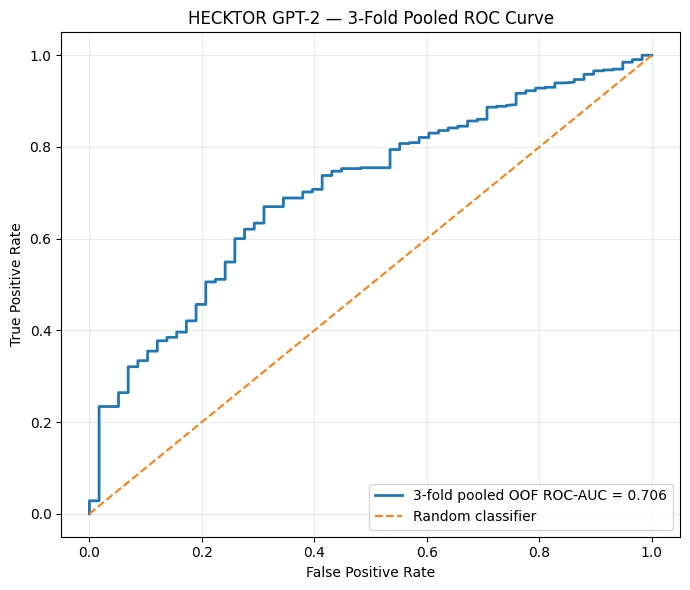

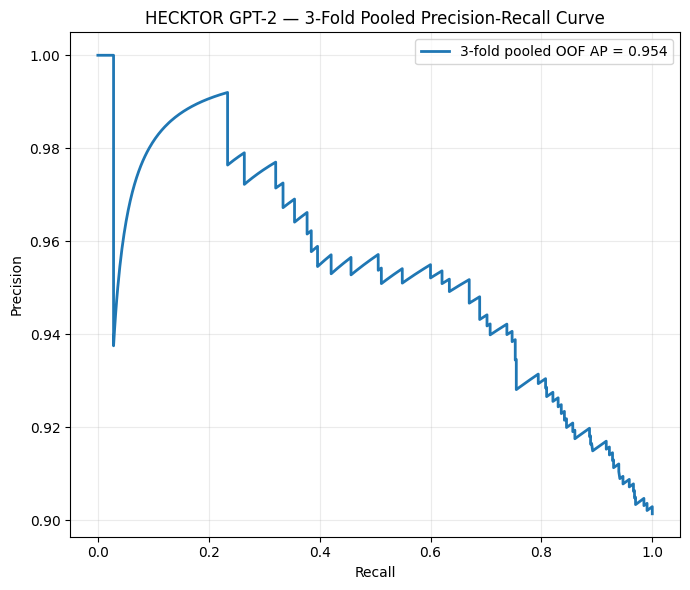


All 3-fold experiment outputs saved to:
/content/drive/MyDrive/HECKTOR_GPT2_3Fold_results


In [3]:

# ============================================================
# HECKTOR GPT-2 — STRATIFIED 3-FOLD CROSS-VALIDATION
# Entire dataset | Final 2 GPT-2 blocks unfrozen
# Updated natural-language clinical narrative
# ============================================================

import os
import gc
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import GPT2Tokenizer, GPT2Model

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# ============================================================
# 1. SETTINGS AND REPRODUCIBILITY
# ============================================================

SEED = 42

def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

MODEL_NAME = "openai-community/gpt2"
DATA_FILE = "HPV2025.xlsx"

N_SPLITS = 3
EPOCHS = 500

BATCH_SIZE = 64
MAX_LENGTH = 128

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1

OUT_DIR = Path("/content/drive/MyDrive/HECKTOR_GPT2_3Fold_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. LOAD THE ENTIRE DATASET
# ============================================================

if not os.path.exists(DATA_FILE):
    import gdown

    downloaded = gdown.download(
        id="1DGDH2e6dEkpdwwtCvH6ds1CwJT2Hdmkv",
        output=DATA_FILE,
        quiet=False
    )

    if downloaded is None or not os.path.exists(DATA_FILE):
        raise FileNotFoundError("Could not download HPV2025.xlsx.")

df = pd.read_excel(DATA_FILE)

TARGET = "HPV Status"

FEATURES = [
    "Age",
    "Gender",
    "Tobacco Consumption",
    "Alcohol Consumption",
    "Performance Status",
    "T-stage",
    "N-stage",
    "M-stage"
]

missing = [c for c in [TARGET] + FEATURES if c not in df.columns]

if missing:
    raise KeyError(f"Required columns missing: {missing}")


# ============================================================
# 3. NORMALISE HPV TARGET
# ============================================================

def normalize_target(x):
    if pd.isna(x):
        return np.nan

    s = str(x).strip().lower()

    if s in {"0", "0.0", "negative", "neg", "false", "no"}:
        return 0

    if s in {"1", "1.0", "positive", "pos", "true", "yes"}:
        return 1

    try:
        n = float(s)
        if n in (0, 1):
            return int(n)
    except (ValueError, TypeError):
        pass

    return np.nan


df["HPV_Label"] = df[TARGET].apply(normalize_target)

invalid_count = int(df["HPV_Label"].isna().sum())

df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)

df = df[FEATURES + ["HPV_Label"]].copy()
df = df.reset_index(drop=True)

if df.empty:
    raise ValueError("No valid HPV labels found.")

class_counts = df["HPV_Label"].value_counts().reindex(
    [0, 1], fill_value=0
)

if (class_counts < N_SPLITS).any():
    raise ValueError(
        "Each HPV class needs at least 3 patients for stratified "
        f"3-fold cross-validation. Counts: {class_counts.to_dict()}"
    )

print("\nEntire dataset:", df.shape)
print("Invalid/missing target rows removed:", invalid_count)
print("HPV class counts (0=negative, 1=positive):")
print(class_counts)


# ============================================================
# 4. CLINICAL NARRATIVE
# ============================================================

def display_value(x):
    if pd.isna(x):
        return "Unknown"

    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))

    return str(x).strip()


def format_stage(x, prefix):
    value = display_value(x)

    if value == "Unknown" or value.upper().startswith(prefix):
        return value

    try:
        n = float(value)

        if n.is_integer():
            return f"{prefix}{int(n)}"

    except ValueError:
        pass

    return f"{prefix}{value}"


def patient_to_text(row):

    gender = display_value(row["Gender"])
    smoker = display_value(row["Tobacco Consumption"])
    alcohol = display_value(row["Alcohol Consumption"])

    performance = display_value(row["Performance Status"])

    return (
        "Q: Predict this patient's Human Papillomavirus (HPV) status "
        "using the clinical information available.\n"
        f"This patient is a {display_value(row['Age'])}-year-old. "
        f"Gender is {gender}. "
        f"Tobacco consumption is {smoker}. "
        f"Alcohol consumption is {alcohol}. "
        f"Performance status is {performance}. "
        f"Tumour stage is {format_stage(row['T-stage'], 'T')}. "
        f"Nodal stage is {format_stage(row['N-stage'], 'N')}. "
        f"Metastatic stage is {format_stage(row['M-stage'], 'M')}.\n"
        "Is this patient HPV positive? Answer with only Yes or No.\n"
        "A:"
    )


# ============================================================
# 5. TOKENIZER AND DATASET
# ============================================================

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token


class HPVTextDataset(Dataset):

    def __init__(self, texts, labels):
        self.items = []

        for text, label in zip(texts, labels):

            enc = tokenizer(
                text,
                max_length=MAX_LENGTH,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            self.items.append((
                enc["input_ids"].squeeze(0),
                enc["attention_mask"].squeeze(0),
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):

        ids, mask, label = self.items[index]

        return {
            "input_ids": ids,
            "attention_mask": mask,
            "label": torch.tensor(label, dtype=torch.long)
        }


# ============================================================
# 6. GPT-2 CLASSIFIER
# ============================================================

class HPVNetGPT2Text(nn.Module):

    def __init__(self):
        super().__init__()

        self.gpt2 = GPT2Model.from_pretrained(MODEL_NAME)
        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        hidden_size = self.gpt2.config.hidden_size

        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(DROPOUT),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(DROPOUT),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask):

        out = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        ).last_hidden_state

        positions = attention_mask.sum(dim=1) - 1

        pooled = out[
            torch.arange(out.size(0), device=out.device),
            positions
        ]

        return self.classifier(pooled)


# ============================================================
# 7. FREEZE GPT-2 EXCEPT FINAL TWO BLOCKS
# ============================================================

def initialise_model():

    model = HPVNetGPT2Text().to(device)

    # Freeze the complete GPT-2 backbone.
    for param in model.gpt2.parameters():
        param.requires_grad = False

    # Unfreeze only the final two transformer blocks.
    for block in model.gpt2.h[-2:]:
        for param in block.parameters():
            param.requires_grad = True

    # Keep the separate classification head trainable.
    for param in model.classifier.parameters():
        param.requires_grad = True

    trainable = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    total = sum(p.numel() for p in model.parameters())

    print(f"Trainable parameters: {trainable:,} / {total:,}")
    print("Trainable GPT-2 blocks: final 2")
    print("Classification head: trainable")

    return model


# ============================================================
# 8. TRAINING AND EVALUATION HELPERS
# ============================================================

def calculate_class_weights(labels):

    counts = np.bincount(labels, minlength=2)

    weights = len(labels) / (2 * np.maximum(counts, 1))

    return torch.tensor(
        weights,
        dtype=torch.float32,
        device=device
    )


def weighted_loss(logits, labels, class_weights):

    losses = nn.functional.cross_entropy(
        logits,
        labels,
        reduction="none"
    )

    return (losses * class_weights[labels]).mean()


def get_scores(model, loader):

    model.eval()

    scores = []
    labels = []

    with torch.no_grad():

        for batch in loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)

            logits = model(ids, mask)

            probabilities = torch.softmax(logits, dim=1)[:, 1]

            scores.extend(probabilities.cpu().numpy())
            labels.extend(batch["label"].numpy())

    return (
        np.asarray(scores),
        np.asarray(labels, dtype=int)
    )


def evaluate_loss(model, loader, class_weights):

    model.eval()

    total_loss = 0.0
    total_examples = 0

    with torch.no_grad():

        for batch in loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            logits = model(ids, mask)

            loss = weighted_loss(
                logits,
                labels,
                class_weights
            )

            n = len(labels)

            total_loss += loss.item() * n
            total_examples += n

    return total_loss / max(total_examples, 1)


def choose_threshold(scores, labels):

    thresholds = np.unique(
        np.r_[0.0, scores, 1.0]
    )

    results = [
        (
            float(t),
            balanced_accuracy_score(labels, scores >= t)
        )
        for t in thresholds
    ]

    return max(
        results,
        key=lambda x: (x[1], -abs(x[0] - 0.5))
    )


# ============================================================
# 9. IMPUTATION — FIT ON TRAINING DATA ONLY
# ============================================================

def impute_splits(train_df, val_df, heldout_df):

    train_df = train_df.copy()
    val_df = val_df.copy()
    heldout_df = heldout_df.copy()

    fill_values = {}

    for col in FEATURES:

        if pd.api.types.is_numeric_dtype(train_df[col]):

            value = train_df[col].median()

            if pd.isna(value):
                value = 0

        else:

            modes = (
                train_df[col]
                .dropna()
                .astype(str)
                .mode()
            )

            value = modes.iloc[0] if not modes.empty else "Unknown"

        fill_values[col] = value

        for split in (train_df, val_df, heldout_df):

            split[col] = split[col].fillna(value)

            if split[col].dtype == object:

                split[col] = (
                    split[col]
                    .astype(str)
                    .replace({
                        "": "Unknown",
                        "nan": "Unknown",
                        "None": "Unknown"
                    })
                )

    return train_df, val_df, heldout_df, fill_values


# ============================================================
# 10. STRATIFIED 3-FOLD CROSS-VALIDATION
# ============================================================

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

fold_results = []
oof_records = []

for fold, (outer_train_idx, heldout_idx) in enumerate(
    skf.split(df[FEATURES], df["HPV_Label"]),
    start=1
):

    print("\n" + "=" * 65)
    print(f"STARTING FOLD {fold}/{N_SPLITS}")
    print("=" * 65)

    seed_everything(SEED + fold)

    # Outer training data and held-out fold.
    outer_train_df = df.iloc[outer_train_idx].copy()
    heldout_df = df.iloc[heldout_idx].copy()

    # Inner training/validation split.
    inner_train_df, val_df = train_test_split(
        outer_train_df,
        test_size=0.20,
        random_state=SEED + fold,
        stratify=outer_train_df["HPV_Label"]
    )

    # Impute using inner training data only.
    train_df, val_df, heldout_df, fill_values = impute_splits(
        inner_train_df,
        val_df,
        heldout_df
    )

    y_train = train_df["HPV_Label"].to_numpy(dtype=int)
    y_val = val_df["HPV_Label"].to_numpy(dtype=int)
    y_heldout = heldout_df["HPV_Label"].to_numpy(dtype=int)

    print("Training examples:", len(train_df))
    print("Validation examples:", len(val_df))
    print("Held-out fold examples:", len(heldout_df))

    print("Training class counts:", np.bincount(y_train, minlength=2))
    print("Validation class counts:", np.bincount(y_val, minlength=2))
    print("Held-out class counts:", np.bincount(y_heldout, minlength=2))

    if len(np.unique(y_val)) < 2:
        raise ValueError(
            f"Fold {fold}: validation split does not contain both classes."
        )

    if len(np.unique(y_heldout)) < 2:
        raise ValueError(
            f"Fold {fold}: held-out fold does not contain both classes."
        )

    # Build clinical narratives.
    train_texts = [
        patient_to_text(row) for _, row in train_df.iterrows()
    ]

    val_texts = [
        patient_to_text(row) for _, row in val_df.iterrows()
    ]

    heldout_texts = [
        patient_to_text(row) for _, row in heldout_df.iterrows()
    ]

    # Create datasets.
    train_ds = HPVTextDataset(train_texts, y_train)
    val_ds = HPVTextDataset(val_texts, y_val)
    heldout_ds = HPVTextDataset(heldout_texts, y_heldout)

    loader_args = {
        "batch_size": BATCH_SIZE,
        "num_workers": 0,
        "pin_memory": torch.cuda.is_available()
    }

    generator = torch.Generator().manual_seed(SEED + fold)

    train_loader = DataLoader(
        train_ds,
        shuffle=True,
        generator=generator,
        **loader_args
    )

    val_loader = DataLoader(
        val_ds,
        shuffle=False,
        **loader_args
    )

    heldout_loader = DataLoader(
        heldout_ds,
        shuffle=False,
        **loader_args
    )

    # A fresh pretrained GPT-2 model is created for every fold.
    model = initialise_model()

    class_weights = calculate_class_weights(y_train)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # Select best checkpoint using validation PR-AUC.
    best_val_ap = -float("inf")
    best_state = None
    best_epoch = 0
    best_threshold = 0.5


    history = []

    # --------------------------------------------------------
    # TRAINING LOOP
    # --------------------------------------------------------

    for epoch in range(1, EPOCHS + 1):

        model.train()

        loss_sum = 0.0
        n_sum = 0

        for batch in train_loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(ids, mask)

            loss = weighted_loss(
                logits,
                labels,
                class_weights
            )

            loss.backward()
            optimizer.step()

            n = len(labels)

            loss_sum += loss.item() * n
            n_sum += n

        train_loss = loss_sum / max(n_sum, 1)

        val_loss = evaluate_loss(
            model,
            val_loader,
            class_weights
        )

        val_scores, val_labels = get_scores(
            model,
            val_loader
        )

        val_auc = roc_auc_score(val_labels, val_scores)
        val_ap = average_precision_score(val_labels, val_scores)

        threshold, val_ba = choose_threshold(
            val_scores,
            val_labels
        )

        history.append({
            "Fold": fold,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Validation_Loss": val_loss,
            "Validation_ROC_AUC": val_auc,
            "Validation_PR_AUC": val_ap,
            "Validation_Balanced_Accuracy": val_ba,
            "Validation_Threshold": threshold
        })

        # Save the best validation PR-AUC checkpoint.
        if val_ap > best_val_ap:

            best_val_ap = float(val_ap)
            best_epoch = epoch
            best_threshold = threshold

            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }


    # Save fold training history.
    pd.DataFrame(history).to_csv(
        OUT_DIR / f"fold_{fold}_training_history.csv",
        index=False
    )

    # Restore the best validation checkpoint.
    if best_state is None:
        raise RuntimeError(f"No checkpoint was saved for fold {fold}.")

    model.load_state_dict(best_state)

    fold_checkpoint = OUT_DIR / f"fold_{fold}_best_model.pth"
    torch.save(best_state, fold_checkpoint)

    print(
        f"\nFold {fold} best epoch: {best_epoch} | "
        f"Validation PR-AUC: {best_val_ap:.4f} | "
        f"Threshold: {best_threshold:.4f}"
    )

    # --------------------------------------------------------
    # EVALUATE HELD-OUT FOLD ONCE
    # --------------------------------------------------------

    heldout_scores, heldout_labels = get_scores(
        model,
        heldout_loader
    )

    heldout_preds = (
        heldout_scores >= best_threshold
    ).astype(int)

    fold_auc = roc_auc_score(
        heldout_labels,
        heldout_scores
    )

    fold_ap = average_precision_score(
        heldout_labels,
        heldout_scores
    )

    fold_ba = balanced_accuracy_score(
        heldout_labels,
        heldout_preds
    )

    fold_f1 = f1_score(
        heldout_labels,
        heldout_preds,
        zero_division=0
    )

    cm = confusion_matrix(
        heldout_labels,
        heldout_preds,
        labels=[0, 1]
    )

    print(f"\n========== FOLD {fold} HELD-OUT RESULTS ==========")

    print(classification_report(
        heldout_labels,
        heldout_preds,
        labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4,
        zero_division=0
    ))

    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(cm)

    print(
        f"ROC-AUC={fold_auc:.4f} | "
        f"PR-AUC={fold_ap:.4f} | "
        f"Balanced Accuracy={fold_ba:.4f} | "
        f"F1={fold_f1:.4f}"
    )

    fold_results.append({
        "Fold": fold,
        "Best_Epoch": best_epoch,
        "Validation_PR_AUC": best_val_ap,
        "Threshold": best_threshold,
        "Heldout_ROC_AUC": fold_auc,
        "Heldout_PR_AUC": fold_ap,
        "Heldout_Balanced_Accuracy": fold_ba,
        "Heldout_F1": fold_f1,
        "TN": cm[0, 0],
        "FP": cm[0, 1],
        "FN": cm[1, 0],
        "TP": cm[1, 1],
        "Heldout_N": len(heldout_labels)
    })

    # Save out-of-fold predictions.
    for i in range(len(heldout_labels)):

        oof_records.append({
            "Fold": fold,
            "True_Label": int(heldout_labels[i]),
            "HPV_Positive_Score": float(heldout_scores[i]),
            "Predicted_Label": int(heldout_preds[i]),
            "Threshold": float(best_threshold)
        })

    # Save held-out fold predictions.
    pd.DataFrame({
        "True_Label": heldout_labels,
        "HPV_Positive_Score": heldout_scores,
        "Predicted_Label": heldout_preds,
        "Threshold": best_threshold
    }).to_csv(
        OUT_DIR / f"fold_{fold}_heldout_predictions.csv",
        index=False
    )

    # Release memory before next fold.
    del model, optimizer, train_loader, val_loader, heldout_loader
    del train_ds, val_ds, heldout_ds, best_state

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 11. SAVE FOLD RESULTS AND MEAN ± STANDARD DEVIATION
# ============================================================

fold_results_df = pd.DataFrame(fold_results)

fold_results_df.to_csv(
    OUT_DIR / "3fold_results_by_fold.csv",
    index=False
)

metrics = [
    "Heldout_ROC_AUC",
    "Heldout_PR_AUC",
    "Heldout_Balanced_Accuracy",
    "Heldout_F1"
]

summary_rows = []

for metric in metrics:

    summary_rows.append({
        "Metric": metric,
        "Mean": fold_results_df[metric].mean(),
        "Standard_Deviation": fold_results_df[metric].std(ddof=1)
    })

summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUT_DIR / "3fold_mean_and_standard_deviation.csv",
    index=False
)

print("\n" + "=" * 65)
print("THREE-FOLD CROSS-VALIDATION SUMMARY")
print("=" * 65)

print(fold_results_df.to_string(index=False))

print("\nMean ± Standard Deviation:")
print(summary_df.to_string(index=False))


# ============================================================
# 12. POOLED OUT-OF-FOLD PREDICTIONS
# ============================================================

oof_df = pd.DataFrame(oof_records)

oof_df.to_csv(
    OUT_DIR / "all_out_of_fold_predictions.csv",
    index=False
)

oof_labels = oof_df["True_Label"].to_numpy(dtype=int)

oof_scores = oof_df["HPV_Positive_Score"].to_numpy(dtype=float)

oof_preds = oof_df["Predicted_Label"].to_numpy(dtype=int)

pooled_auc = roc_auc_score(oof_labels, oof_scores)

pooled_ap = average_precision_score(oof_labels, oof_scores)

pooled_ba = balanced_accuracy_score(oof_labels, oof_preds)

pooled_f1 = f1_score(
    oof_labels,
    oof_preds,
    zero_division=0
)

pooled_cm = confusion_matrix(
    oof_labels,
    oof_preds,
    labels=[0, 1]
)

print("\n========== POOLED OUT-OF-FOLD RESULTS ==========")

print(
    f"ROC-AUC={pooled_auc:.4f} | "
    f"PR-AUC={pooled_ap:.4f} | "
    f"Balanced Accuracy={pooled_ba:.4f} | "
    f"F1={pooled_f1:.4f}"
)

print("Pooled confusion matrix [[TN, FP], [FN, TP]]:")
print(pooled_cm)

pooled_summary = pd.DataFrame([{
    "Pooled_OOF_ROC_AUC": pooled_auc,
    "Pooled_OOF_PR_AUC": pooled_ap,
    "Pooled_OOF_Balanced_Accuracy": pooled_ba,
    "Pooled_OOF_F1": pooled_f1,
    "TN": pooled_cm[0, 0],
    "FP": pooled_cm[0, 1],
    "FN": pooled_cm[1, 0],
    "TP": pooled_cm[1, 1]
}])

pooled_summary.to_csv(
    OUT_DIR / "pooled_out_of_fold_metrics.csv",
    index=False
)


# ============================================================
# 13. POOLED OUT-OF-FOLD ROC CURVE
# ============================================================

fpr, tpr, roc_thresholds = roc_curve(
    oof_labels,
    oof_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"3-fold pooled OOF ROC-AUC = {pooled_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HECKTOR GPT-2 — 3-Fold Pooled ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "3fold_pooled_ROC_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "FPR": fpr,
    "TPR": tpr,
    "Threshold": roc_thresholds
}).to_csv(
    OUT_DIR / "3fold_pooled_ROC_coordinates.csv",
    index=False
)


# ============================================================
# 14. POOLED OUT-OF-FOLD PRECISION-RECALL CURVE
# ============================================================

precision, recall, pr_thresholds = precision_recall_curve(
    oof_labels,
    oof_scores
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"3-fold pooled OOF AP = {pooled_ap:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HECKTOR GPT-2 — 3-Fold Pooled Precision-Recall Curve")
plt.legend(loc="best")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "3fold_pooled_PR_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "Precision": precision,
    "Recall": recall
}).to_csv(
    OUT_DIR / "3fold_pooled_PR_coordinates.csv",
    index=False
)


# ============================================================
# 15. SAVE EXPERIMENT SETTINGS
# ============================================================

settings = {
    "Dataset": "HECKTOR",
    "Model": MODEL_NAME,
    "Target": TARGET,
    "Features": ", ".join(FEATURES),
    "Number_of_Features": len(FEATURES),
    "Cross_Validation": "Stratified 3-fold",
    "Dataset_Usage": "Entire dataset; each patient held out once",
    "Inner_Validation_Split": "20% of each outer training fold",
    "Imputation": "Fitted on inner training data only",
    "Epochs_Maximum": EPOCHS,
    "Early_Stopping": False,
    "Training_Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Dropout": DROPOUT,
    "Max_Length": MAX_LENGTH,
    "Optimizer": "AdamW",
    "Class_Weighted_Loss": True,
    "GPT2_Backbone": "Partially frozen",
    "GPT2_Trainable_Blocks": "Final 2",
    "Classifier_Head": "Trainable",
    "Checkpoint_Selection": "Best inner-validation PR-AUC",
    "Threshold_Selection": "Maximum inner-validation balanced accuracy",
    "ROC_PR_Curves": "Pooled out-of-fold predictions"
}

pd.DataFrame([settings]).to_csv(
    OUT_DIR / "3fold_experiment_settings.csv",
    index=False
)

print("\nAll 3-fold experiment outputs saved to:")
print(OUT_DIR.resolve())
